# The box game

There is a 1000 x 1000 grid and a hidden treasure at `true_treasure` which you want to find.

Every week you move to a position in the grid and an _oracle_ gives you the distance to the treasure with a 10% error.

Here we'll use Numpyro to locate it.

Here we'll use the ELBO method (rather than MCMC) to locate the maximum posterior probability at each iteration.

In [1]:
import jax
import jax.numpy as jnp
import numpyro
import numpyro.distributions as dist
#from numpyro.infer import MCMC, NUTS

from numpyro.infer import SVI, Trace_ELBO
from numpyro.infer.autoguide import AutoDelta
import optax

import matplotlib.pyplot as plt

key = jax.random.PRNGKey(1234)

/home/carlos/gits/otros/datanalytics_code/2026-box-game/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Initial point and error.

The defined `sd` will generate an error less than 10% with a confidence of 95%.

In [2]:

true_treasure = jnp.array([320.0, 750.0])
sd_error = .05 # 95% confidence in a 10% error

## Model + Random Approach 

Here 

$$d_o / d_r \sim \text{Norm}(1, \sigma)$$

where $d_o$ and $d_r$ are the observed and real distances between a location and the treasure.

The prior is uniform on a 1000 x 1000 canvas.

In [3]:

def model(visited_locations, observed_distances):
    """
    visited_locations: (N, 2) array of (x, y) coordinates visited
    observed_distances: (N,) array of noisy distance measurements
    """

    # Constants
    obs_sd = sd_error

    # Prior: treasure location uniform on [0, 1000] x [0, 1000]
    tx = numpyro.sample("tx", dist.Uniform(0, 1000))
    ty = numpyro.sample("ty", dist.Uniform(0, 1000))

    treasure = jnp.array([tx, ty])

    # Expected distances from treasure to each visited location
    expected_distances = jnp.sqrt(jnp.sum((visited_locations - treasure) ** 2, axis=1))

    numpyro.sample(
        "obs",
        dist.LogNormal(jnp.log(expected_distances), obs_sd),
        obs=observed_distances
    )

First we generate a number of random points to see whether the process can locate the treasure using a _random_ approach. 

In [4]:
N = 20
key, k1, k2, k3 = jax.random.split(key, 4)
visited_locations = jax.random.uniform(k1, shape=(N, 2), minval=0, maxval=1000)
true_distances = jnp.sqrt(jnp.sum((visited_locations - true_treasure) ** 2, axis=1))
observed_distances = true_distances * (1 + sd_error *jax.random.normal(k2, shape=true_distances.shape))

In [5]:
guide = AutoDelta(model)

optimizer = optax.adam(learning_rate=0.01)

svi = SVI(model, guide, optimizer, loss=Trace_ELBO())

svi_result = svi.run(
    k3,
    num_steps=5000,
    visited_locations=visited_locations,
    observed_distances=observed_distances,
)

params = svi_result.params
map_estimates = guide.median(params)

print(map_estimates)  # {"tx": ..., "ty": ...}

100%|██████████| 5000/5000 [00:01<00:00, 3208.70it/s, init loss: 1185.5166, avg. loss [4751-5000]: 100.6446]


{'tx': Array(322.77164, dtype=float32), 'ty': Array(743.6216, dtype=float32)}


## Targeted Approach

Here, we'll move towards the target as new information comes in.

We'll start from a random position, calculate, move towards the most likely position, and iterate.

For that purpose, we'll create the next two functions that embed the process above.

In [6]:
def reported_distance(location, treasure, k):
    new_key, subkey = jax.random.split(k)
    noise = jax.random.normal(subkey, shape=()) * sd_error
    distance = jnp.sqrt(jnp.sum((location - treasure) ** 2))
    observed_distance = distance * (1 + noise)
    return observed_distance, new_key

In [7]:
def get_map(visited_locations, observed_distances, key, init_loc=None):
    new_key, subkey = jax.random.split(key)

    guide = AutoDelta(model)

    optimizer = optax.adam(learning_rate=0.01)

    svi = SVI(model, guide, optimizer, loss=Trace_ELBO())

    svi_result = svi.run(
        k3,
        num_steps=5000,
        visited_locations=visited_locations,
        observed_distances=observed_distances,
    )

    params = svi_result.params
    params = guide.median(params)

    return params, new_key

Main loop: starting with a _random_ position, we'll iteratively move towards the _most likely_ treasure position.

In [8]:
results = {}

new_key = key

for i in range(20):

    if i == 0:
        new_point = jnp.array([500.0, 500.0])
    else:
        new_point = next_point

    print(new_point)

    new_distance, new_key = reported_distance(new_point, true_treasure, new_key)

    results[i] = {
        'point': new_point,
        'distance' : new_distance
    }

    visited_locations  = jnp.vstack([r['point'] for r in results.values()])
    observed_distances = jnp.stack([r['distance'] for r in results.values()])

    next_point, new_key = get_map(visited_locations, observed_distances, new_key)
    next_point = jnp.array([next_point['tx'], next_point['ty']])


[500. 500.]


100%|██████████| 5000/5000 [00:01<00:00, 3214.23it/s, init loss: 70.4786, avg. loss [4751-5000]: 17.4570]


[245.28822 333.34683]


100%|██████████| 5000/5000 [00:01<00:00, 3314.11it/s, init loss: 321.4755, avg. loss [4751-5000]: 21.4258]


[323.849  748.2381]


100%|██████████| 5000/5000 [00:01<00:00, 3254.96it/s, init loss: 3929.9536, avg. loss [4751-5000]: 20.8773]


... (30 outputs left out)

[320.15552 749.97675]


100%|██████████| 5000/5000 [00:01<00:00, 3463.73it/s, init loss: 92477.9844, avg. loss [4751-5000]: 28964.2480]


[340.48734 729.4977 ]


100%|██████████| 5000/5000 [00:01<00:00, 3562.52it/s, init loss: 93452.6719, avg. loss [4751-5000]: 50043.9453]


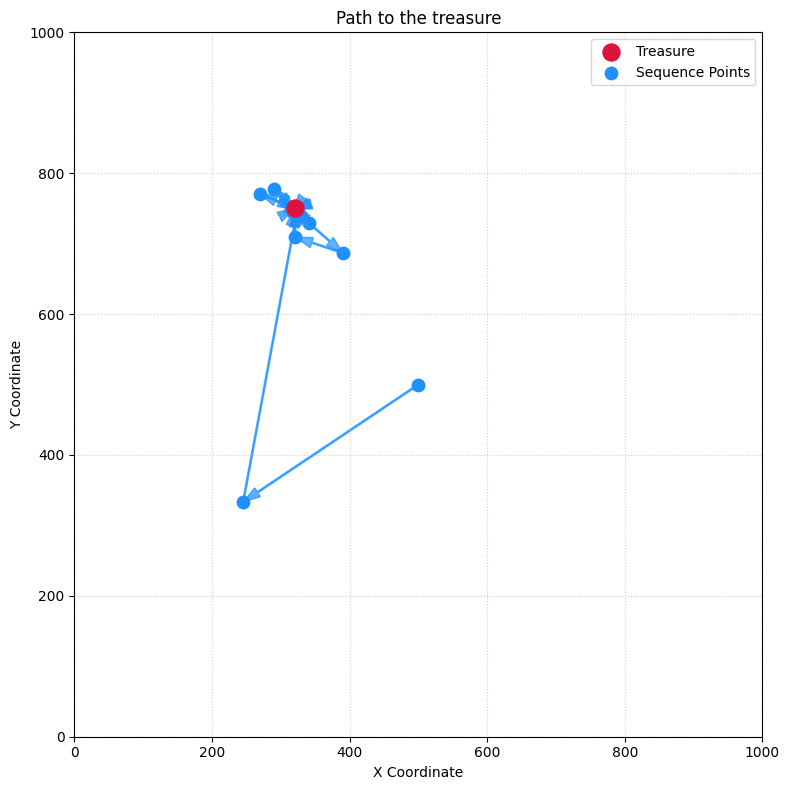

In [9]:
point = true_treasure

path = jnp.vstack([r['point'] for r in results.values()])


plt.figure(figsize=(8, 8))

# Set the canvas limits (1000 x 1000)
plt.xlim(0, 1000)
plt.ylim(0, 1000)

# 2. Plot the first point in a distinct color
plt.scatter(point[0], point[1], color='crimson', s=150, label='Treasure', zorder=5)

# 3. Plot the other points and join them with arrows
x_coords = path[:, 0]
y_coords = path[:, 1]

# Plot dots for the sequence points
plt.scatter(x_coords, y_coords, color='dodgerblue', s=80, label='Sequence Points', zorder=4)


for i in range(len(path) - 1):
    x_start, y_start = path[i]
    x_end, y_end = path[i+1]

    dx = x_end - x_start
    dy = y_end - y_start

    # plt.arrow draws the connection
    plt.arrow(x_start, y_start, dx, dy,
                head_width=15,          # Width of the arrow head
                head_length=25,         # Length of the arrow head
                fc='dodgerblue',        # Face color
                ec='dodgerblue',        # Edge color
                length_includes_head=True, # Tip ends exactly at the point
                alpha=0.7,
                width=2)                # Line thickness

# Aesthetics
plt.title("Path to the treasure")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()